In [ ]:
# These notebooks live in notebooks/d1_dev/ but use paths relative to the repo root
# (data/, protocol/, reports/, ...) and import from src/: go back to the root first.
# The test makes it harmless to run twice, or to run from the root.
import os
from pathlib import Path

if not Path("src").exists():
    os.chdir(Path.cwd().parents[1])

# 02 — CNN baseline

A small convolutional network trained from scratch on 128x128 RGB images, with seed 42 only.
Two scopes are trained separately: the full dataset (Photo vs the 4 other origins) and Photo vs Text only.

In [1]:
import os
import time
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
import sklearn
import tensorflow as tf
import keras
from src.utils import CACHE, METRICS, class_weights, evaluate, load_images, plot_curves

T0 = time.time()
gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    raise SystemExit("No GPU found by TensorFlow: check the kernel and the CUDA libraries (see README) before running this notebook.")
tf.config.experimental.set_memory_growth(gpus[0], True)
print("GPU:", gpus)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| Pillow", PIL.__version__)

REPORTS = Path("reports")
CACHE.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)
SEED, SIZE, EPOCHS, BATCH = 42, 128, 20, 32

I0000 00:00:1791489861.804189   55376 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791489863.184354   55376 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow 2.22.0-rc0 | Keras 3.16.0.dev2026100504 | numpy 2.5.3 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2 | Pillow 12.3.0


In [2]:
manifest = pd.read_csv("protocol/manifest.csv")
df = manifest[manifest["drop_reason"].isna()].reset_index(drop=True)
counts = pd.crosstab(df["origin"], df["split"], margins=True, margins_name="total")
print(counts[["train", "val", "test", "total"]])

splits = {s: df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
X = {s: load_images(d, SIZE) for s, d in splits.items()}
y = {s: d["label"].to_numpy() for s, d in splits.items()}
for s in X:
    print(s, X[s].shape, X[s].dtype)

split       train   val  test  total
origin                              
Painting     6997  1499  1500   9996
Photo        6995  1499  1499   9993
Schematics   6236  1336  1336   8908
Sketch        984   211   211   1406
Text         6999  1500  1500   9999
total       28211  6045  6046  40302


train (28211, 128, 128, 3) uint8
val (6045, 128, 128, 3) uint8
test (6046, 128, 128, 3) uint8


Rescaling maps pixels to 0-1; three Conv2D(3x3) + MaxPooling blocks (16, 32, 64 filters) shrink the image to 14x14x64 before Flatten and Dense(64).
Convolution filters share weights across positions, so the 826,529 parameters are mostly the 802,880 in Dense(64) after Flatten.
Loss and optimiser are the same as in the MLP: class-weighted binary cross-entropy and Adam at 1e-3.

In [3]:
def build_cnn(seed=SEED):
    keras.utils.set_random_seed(seed)
    layers = [keras.Input((SIZE, SIZE, 3)), keras.layers.Rescaling(1 / 255)]
    for filters in [16, 32, 64]:
        layers += [keras.layers.Conv2D(filters, 3, activation="relu"), keras.layers.MaxPooling2D()]
    layers += [keras.layers.Flatten(), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(1, activation="sigmoid")]
    model = keras.Sequential(layers, name="cnn_baseline")
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return model

cnn = build_cnn()
cnn.summary()

Model: "cnn_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       802,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 826,529 (3.15 MB)

 Trainable params: 826,529 (3.15 MB)

 Non-trainable params: 0 (0.00 B)

## Training: two scopes, seed 42

To make train and validation losses comparable, validation is passed as (x_val, y_val, sample_weight_val) with the same class weights as training.
The accuracy metric is not weighted (validation accuracy printed below equals plain accuracy), so only the losses are class-weighted.
Each scope is trained from scratch for 20 epochs and the last-epoch weights are kept; test predictions are stored here but only reported in the Results section.

In [4]:
SCOPES = {"full": sorted(df["origin"].unique()), "photo_vs_text": ["Photo", "Text"]}
mask = {(sc, s): splits[s]["origin"].isin(o).to_numpy() for sc, o in SCOPES.items() for s in splits}

def run_scope(scope):
    tr, va = mask[(scope, "train")], mask[(scope, "val")]
    cw = class_weights(y["train"][tr])
    sw_val = np.where(y["val"][va] == 1, cw[1], cw[0])
    model = build_cnn()
    t = time.time()
    hist = model.fit(X["train"][tr], y["train"][tr], validation_data=(X["val"][va], y["val"][va], sw_val),
                     epochs=EPOCHS, batch_size=BATCH, class_weight=cw, verbose=0)
    out = {"history": hist.history, "time_s": time.time() - t, "class_weight": cw,
           "val": evaluate(y["val"][va], model.predict(X["val"][va], verbose=0), splits["val"]["origin"][va]),
           "proba_test": model.predict(X["test"], verbose=0).ravel()}  # full test set, subset later
    keras.backend.clear_session()
    return out

runs = {}
for scope in SCOPES:
    runs[scope] = r = run_scope(scope)
    print(f"{scope:14s}: {r['time_s']:.0f} s | class weights {{0: {r['class_weight'][0]:.3f}, 1: {r['class_weight'][1]:.3f}}}"
          f" | val balanced acc {r['val']['balanced_acc']:.4f}")

full          : 131 s | class weights {0: 0.665, 1: 2.017} | val balanced acc 0.8864


photo_vs_text : 64 s | class weights {0: 1.000, 1: 1.000} | val balanced acc 0.9997


In [5]:
val_table = pd.DataFrame({sc: {m: r["val"][m] for m in METRICS} for sc, r in runs.items()}).T.round(4)
val_table

,precision,recall,f1,balanced_acc,pr_auc,accuracy
full,0.7282,0.8813,0.7975,0.8864,0.8474,0.8890
photo_vs_text,1.0000,0.9993,0.9997,0.9997,1.0000,0.9997


## Learning curves

Losses are class-weighted on both sides and comparable; accuracies are plain (unweighted) accuracies.

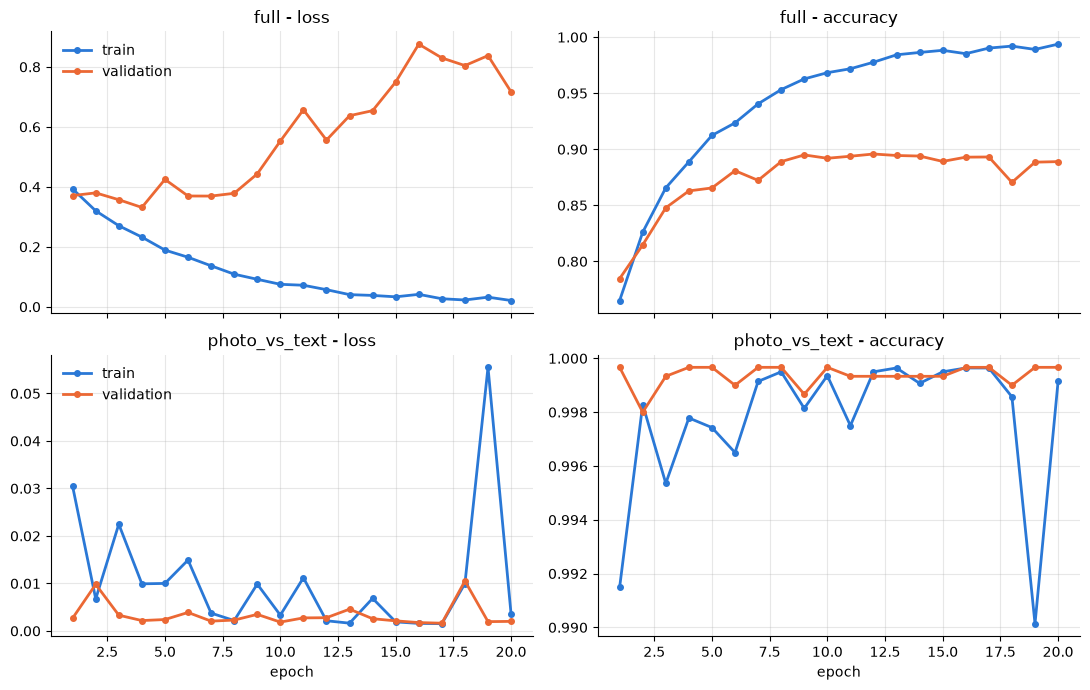

Last epoch (20) unless stated otherwise


,loss,val_loss,min val_loss,epoch of min val_loss,accuracy,val_accuracy,max val_accuracy,epoch of max val_accuracy
full,0.0210,0.7168,0.3313,4.0,0.9938,0.8890,0.8958,12.0
photo_vs_text,0.0035,0.0020,0.0016,17.0,0.9991,0.9997,0.9997,1.0


In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for i, scope in enumerate(SCOPES):
    plot_curves(runs[scope]["history"], scope, axes[i])
for ax in axes[0]:
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(REPORTS / "02_cnn_curves.png", dpi=120)
plt.show()

rows = {}
for sc, r in runs.items():
    h = r["history"]
    rows[sc] = {"loss": h["loss"][-1], "val_loss": h["val_loss"][-1], "min val_loss": min(h["val_loss"]),
                "epoch of min val_loss": int(np.argmin(h["val_loss"])) + 1,
                "accuracy": h["accuracy"][-1], "val_accuracy": h["val_accuracy"][-1],
                "max val_accuracy": max(h["val_accuracy"]), "epoch of max val_accuracy": int(np.argmax(h["val_accuracy"])) + 1}
curves = pd.DataFrame(rows).T
print("Last epoch (20) unless stated otherwise")
curves.round(4)

What I observe

Observed:
- Full scope, epoch 20: train accuracy 0.99, validation accuracy 0.89.
- Validation loss is lowest early in training, then rises while train loss keeps falling.

Meaning: the full-scope CNN probably overfits; Photo vs Text shows no such gap.

## Results on the test set

Test metrics are computed once here, at threshold 0.5, on the natural test distribution of each scope.
The MLP and decision-tree rows are read from reports/test_results.csv (written by 01_mlp.ipynb), not recomputed.

In [7]:
test_eval = {sc: evaluate(y["test"][mask[(sc, "test")]], r["proba_test"][mask[(sc, "test")]],
                          splits["test"]["origin"][mask[(sc, "test")]]) for sc, r in runs.items()}
pt = mask[("photo_vs_text", "test")]
full_on_pt = evaluate(y["test"][pt], runs["full"]["proba_test"][pt], splits["test"]["origin"][pt])

# One shared file for all notebooks: full-scope test rows, one per model
RESULTS = REPORTS / "test_results.csv"
table_full = pd.read_csv(RESULTS, index_col="model", dtype=str)
table_full.loc["cnn (seed 42)"] = {m: f"{test_eval['full'][m]:.4f}" for m in METRICS}
table_full.to_csv(RESULTS)
print("Full scope, test set (n = %d)" % len(y["test"]))
display(table_full)

table_pt = pd.DataFrame({"cnn trained on photo_vs_text": {m: test_eval["photo_vs_text"][m] for m in METRICS},
                         "cnn trained on full scope": {m: full_on_pt[m] for m in METRICS}}).T.round(4)
print("Photo + Text test rows only (n = %d)" % pt.sum())
display(table_pt)

Full scope, test set (n = 6046)


,precision,recall,f1,balanced_acc,pr_auc,accuracy
model,,,,,,
decision_tree_meta,0.9641,0.9853,0.9746,0.9866,0.9849,0.9873
mlp (seed 42),0.5099,0.9093,0.6534,0.8106,0.6152,0.7608
cnn (seed 42),0.7138,0.8719,0.7850,0.8783,0.8353,0.8816


Photo + Text test rows only (n = 2999)


,precision,recall,f1,balanced_acc,pr_auc,accuracy
cnn trained on photo_vs_text,0.9993,0.9993,0.9993,0.9993,1.0000,0.9993
cnn trained on full scope,1.0000,0.8719,0.9316,0.9360,0.9986,0.9360


What I observe

Observed:
- CNN test balanced accuracy is 0.88, above the MLP (0.81) and below the metadata tree.
- CNN Photo precision is higher than the MLP's, its Photo recall lower.

Meaning: the CNN probably raises fewer false Photo alarms but misses more photos, and pixels alone stay below the format-only bar (single seed).

cnn full scope: [[TN FP] [FN TP]] = [[4023, 524], [192, 1307]]
cnn photo_vs_text: [[TN FP] [FN TP]] = [[1499, 1], [1, 1498]]


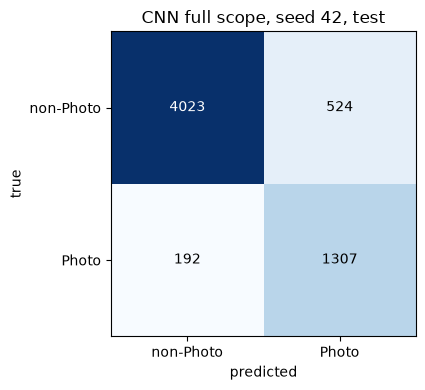

In [8]:
for name, e in [("cnn full scope", test_eval["full"]), ("cnn photo_vs_text", test_eval["photo_vs_text"])]:
    print(f"{name}: [[TN FP] [FN TP]] =", e["cm"].tolist())

cm = test_eval["full"]["cm"]
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["non-Photo", "Photo"])
ax.set_yticks([0, 1], ["non-Photo", "Photo"])
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("CNN full scope, seed 42, test")
plt.tight_layout()
plt.savefig(REPORTS / "02_cnn_confusion.png", dpi=120)
plt.show()

            cnn full scope  cnn photo_vs_text
Painting            0.3173                NaN
Photo               0.1281             0.0007
Schematics          0.0359                NaN
Sketch              0.0000                NaN
Text                0.0000             0.0007


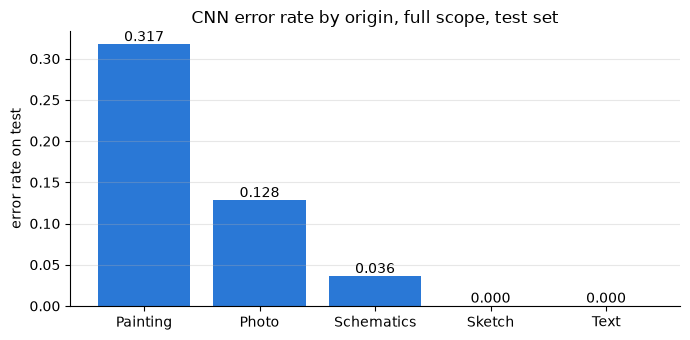

In [9]:
err = pd.DataFrame({"cnn full scope": test_eval["full"]["error_by_origin"],
                    "cnn photo_vs_text": test_eval["photo_vs_text"]["error_by_origin"]})
print(err.round(4))

fig, ax = plt.subplots(figsize=(7, 3.5))
s = err["cnn full scope"]
ax.bar(s.index, s.values, color="#2a78d6")
for i, v in enumerate(s.values):
    ax.text(i, v, f"{v:.3f}", ha="center", va="bottom")
ax.set_ylabel("error rate on test")
ax.set_title("CNN error rate by origin, full scope, test set")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS / "02_cnn_error_by_origin.png", dpi=120)
plt.show()

What I observe

Observed:
- Painting has the highest CNN error rate in the full scope (0.32), ahead of Photo (0.13).
- Sketch and Text have no errors.

Meaning: Painting is probably the main source of false Photo alarms, so Painting vs Photo may be the distinction left to improve.

What I observe

Observed:
- On the same Photo + Text test rows, balanced accuracy is 1.00 for the Photo vs Text CNN and 0.94 for the full-scope CNN.
- The full-scope CNN labels no Text image as Photo; its gap comes from missed photos.

Meaning: Photo vs Text is probably almost solved by a small CNN, and the difficulty of the full task likely comes from the other origins.

## Limits

Images are resized to 128x128 without keeping the aspect ratio, so shape information is distorted.
The metadata tree reaches 0.9866 balanced accuracy on test, so a good CNN score may partly come from format or resolution cues left in the pixels.
To check: this notebook does not test that.

In [10]:
print(f"Total notebook runtime: {(time.time() - T0) / 60:.1f} min")

Total notebook runtime: 3.4 min
